# Ablation — figure & table generator

Regenerates the goal-head **ablation** tables + bar figure from
`results/evaluation/ablation/<model>/{necessity,sufficiency}/<config>/summary.json`
(produced by `scripts/evaluation/eval_ablation_{necessity,sufficiency}.py`, shared machinery in
`scripts/evaluation/ablation_common.py`). Metric = oracle judge on the greedy-decoded frontier value:
*does the completion still implement the frontier description?*

- **Necessity** — ablate the goal heads (`ablated`), compare to a matched random `control`; three
  strategies of increasing strength: `blind_task` (deny the task spec span only),
  `blind_task_and_progress` (spec + progress up to the pivot), `sink` (restrict heads to pos-0).
- **Sufficiency** — spare *only* the goal heads and blind the rest (`ablated`), vs sparing a matched
  random set (`control`). If the goal heads carry the goal, `ablated`≈baseline while `control` collapses.

Canonical runs: `__ctrl=later_half` control (layers ≥ 32), 122- and 250-head goal sets, n=253.
Saves to `notebooks/Figures/ablation/`.

In [1]:
import os, sys
_d=os.getcwd()
while _d!='/' and not os.path.isdir(os.path.join(_d,'src')): _d=os.path.dirname(_d)
sys.path.insert(0,_d); os.chdir(_d)
from src.utils import env_utils
sys.path.insert(0, os.path.join(env_utils.PROJECT_ROOT,'notebooks','fig_n_table_generators'))
import json, glob, re
import numpy as np, matplotlib.pyplot as plt
import figstyle as F; F.set_style()
from rich import print as rich_print
from rich.table import Table

GROUP='ablation'
MODEL='Qwen2.5-Coder-32B-Instruct'
ABL=os.path.join(env_utils.DEFAULT_RESULTS_DIR,'evaluation','ablation',MODEL)

# ── condition palette: baseline / goal-ablated / random-control ──
# goal-ablated is the visually strongest (Okabe-Ito vermillion); baseline blue, control green.
COND_COLOR={'baseline':'#4C72B0', 'ablated':'#D55E00', 'control':'#009E73'}
COND_LABEL={'baseline':'baseline', 'ablated':'goal-ablated', 'control':'random-control'}
DATATYPES=['int','list[int]','list[str]','str']

def _leaf_parts(path):
    leaf=os.path.basename(os.path.dirname(path))
    return dict(re.findall(r'([a-zA-Z_]+)=([^_]+(?:\[[^\]]*\])?)', leaf)), leaf

def load(axis):
    """Return {(budget, strat): summary} for the canonical later_half / n=253 runs of an axis."""
    out={}
    for p in sorted(glob.glob(os.path.join(ABL,axis,'*','summary.json'))):
        leaf=os.path.basename(os.path.dirname(p))
        if '__ctrl=later_half' not in leaf: continue          # canonical control
        s=json.load(open(p))
        if s.get('n')!=253: continue                          # full corpus only
        m=re.search(r'goal(122|250)', leaf); strat=re.search(r'strat=(.+?)__dtype', leaf)
        if not (m and strat): continue
        out[(f'goal{m.group(1)}', strat.group(1))]=s
    return out

NEC=load('necessity')
SUF=load('sufficiency')
print('necessity runs:', sorted(NEC)); print('sufficiency runs:', sorted(SUF))

necessity runs: [('goal122', 'blind_task'), ('goal122', 'blind_task_and_progress'), ('goal122', 'sink'), ('goal250', 'blind_task'), ('goal250', 'blind_task_and_progress'), ('goal250', 'sink')]
sufficiency runs: [('goal122', 'blind_span'), ('goal250', 'blind_span')]


                  Necessity — frontier implement-rate (n=253)                   
┏━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃ strategy                ┃ budget  ┃ baseline ┃ goal-ablated ┃ random-control ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ blind_task              │ goal122 │    0.925 │        0.881 │          0.925 │
│ blind_task              │ goal250 │    0.925 │        0.806 │          0.925 │
│ blind_task_and_progress │ goal122 │    0.925 │        0.372 │          0.929 │
│ blind_task_and_progress │ goal250 │    0.925 │        0.249 │          0.925 │
│ sink                    │ goal122 │    0.925 │        0.854 │          0.925 │
│ sink                    │ goal250 │    0.925 │        0.158 │          0.925 │
└─────────────────────────┴─────────┴──────────┴──────────────┴────────────────┘

wrote /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/ablation/necessity.tex


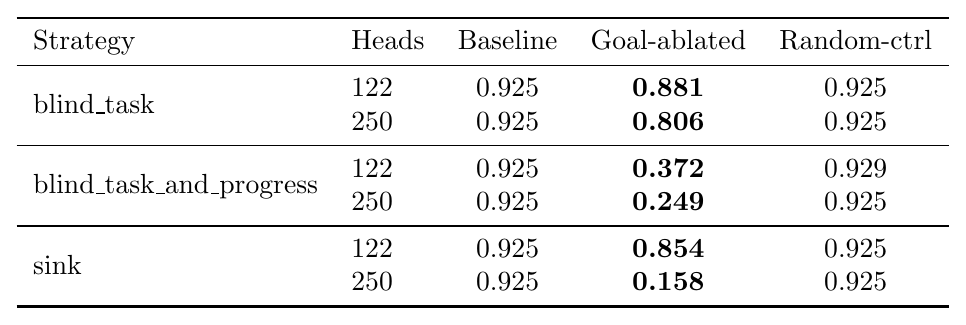

In [2]:
# ── Table: NECESSITY — implementation success (baseline / goal-ablated / random-control) ──
NEC_STRATS=[('blind_task','blind\\_task'),
            ('blind_task_and_progress','blind\\_task\\_and\\_progress'),
            ('sink','sink')]
BUDGETS=['goal122','goal250']

t=Table(title='Necessity — frontier implement-rate (n=253)')
t.add_column('strategy'); t.add_column('budget')
for c in ['baseline','ablated','control']: t.add_column(COND_LABEL[c], justify='right')
for strat,_ in NEC_STRATS:
    for b in BUDGETS:
        o=NEC[(b,strat)]['overall']
        t.add_row(strat, b, f"{o['baseline']:.3f}", f"[bold red]{o['ablated']:.3f}[/bold red]", f"{o['control']:.3f}")
rich_print(t)

# LaTeX (booktabs): rows = strategy x budget, cols = baseline / goal-ablated / random-control
lines=[]
for strat,tex_s in NEC_STRATS:
    for i,b in enumerate(BUDGETS):
        o=NEC[(b,strat)]['overall']
        lead=('\\multirow{2}{*}{%s}'%tex_s) if i==0 else ''
        lines.append(f"{lead} & {b.replace('goal','')} & {o['baseline']:.3f} & \\textbf{{{o['ablated']:.3f}}} & {o['control']:.3f} \\\\")
    if strat!=NEC_STRATS[-1][0]: lines.append('\\midrule')
body='\n'.join(lines)
tex=('\\begin{tabular}{llccc}\n\\toprule\n'
     'Strategy & Heads & Baseline & Goal-ablated & Random-ctrl \\\\\n\\midrule\n'
     + body + '\n\\bottomrule\n\\end{tabular}')
path=F.save_table(tex, GROUP, 'necessity'); print('wrote', path)
img=F.render_latex_table(tex)
img if img is not None else rich_print('[dim](latex preview unavailable; see rich table above)[/dim]')

        Necessity — goal-ablated implement-rate by datatype (n=253)        
┏━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━┳━━━━━━┳━━━━━━┳━━━━━━┳━━━━━━━━━┓
┃ strategy                ┃ budget  ┃  int ┃ list ┃ list ┃  str ┃ overall ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━╇━━━━━━╇━━━━━━╇━━━━━━╇━━━━━━━━━┩
│ blind_task              │ goal122 │ 1.00 │ 0.77 │ 0.86 │ 0.89 │    0.88 │
│ blind_task              │ goal250 │ 0.98 │ 0.70 │ 0.77 │ 0.77 │    0.81 │
│ blind_task_and_progress │ goal122 │ 0.45 │ 0.25 │ 0.36 │ 0.42 │    0.37 │
│ blind_task_and_progress │ goal250 │ 0.32 │ 0.15 │ 0.20 │ 0.31 │    0.25 │
│ sink                    │ goal122 │ 0.94 │ 0.68 │ 0.95 │ 0.83 │    0.85 │
│ sink                    │ goal250 │ 0.12 │ 0.27 │ 0.16 │ 0.09 │    0.16 │
└─────────────────────────┴─────────┴──────┴──────┴──────┴──────┴─────────┘

wrote /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/ablation/necessity_by_datatype.tex


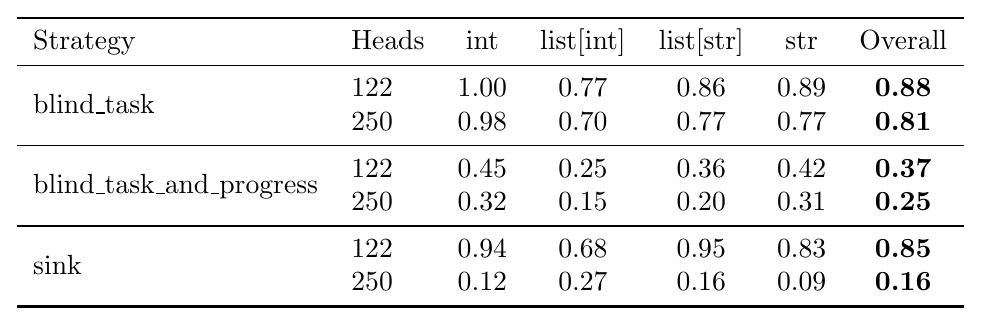

In [3]:
# ── Table: NECESSITY per-datatype (goal-ablated rate; baseline in header row) ──
t=Table(title='Necessity — goal-ablated implement-rate by datatype (n=253)')
t.add_column('strategy'); t.add_column('budget')
for dt in DATATYPES: t.add_column(dt, justify='right')
t.add_column('overall', justify='right')
for strat,_ in NEC_STRATS:
    for b in BUDGETS:
        s=NEC[(b,strat)]
        t.add_row(strat, b, *[f"{s['by_datatype'][dt]['ablated']:.2f}" for dt in DATATYPES],
                  f"[bold red]{s['overall']['ablated']:.2f}[/bold red]")
rich_print(t)

lines=[]
for strat,tex_s in NEC_STRATS:
    for i,b in enumerate(BUDGETS):
        s=NEC[(b,strat)]
        lead=('\\multirow{2}{*}{%s}'%tex_s) if i==0 else ''
        cells_dt=' & '.join(f"{s['by_datatype'][dt]['ablated']:.2f}" for dt in DATATYPES)
        lines.append(f"{lead} & {b.replace('goal','')} & {cells_dt} & \\textbf{{{s['overall']['ablated']:.2f}}} \\\\")
    if strat!=NEC_STRATS[-1][0]: lines.append('\\midrule')
body='\n'.join(lines)
hdr=' & '.join(d.replace('[','{[}').replace(']','{]}') for d in DATATYPES)
tex=('\\begin{tabular}{ll'+'c'*(len(DATATYPES)+1)+'}\n\\toprule\n'
     'Strategy & Heads & '+hdr+' & Overall \\\\\n\\midrule\n'
     + body + '\n\\bottomrule\n\\end{tabular}')
path=F.save_table(tex, GROUP, 'necessity_by_datatype'); print('wrote', path)
img=F.render_latex_table(tex)
img if img is not None else rich_print('[dim](latex preview unavailable)[/dim]')

 Sufficiency — frontier implement-rate (n=253) 
┏━━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ budget  ┃ clean ┃ spare-goal ┃ spare-random ┃
┡━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ goal122 │ 0.925 │      0.806 │        0.103 │
│ goal250 │ 0.925 │      0.913 │        0.087 │
└─────────┴───────┴────────────┴──────────────┘

wrote /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/ablation/sufficiency.tex


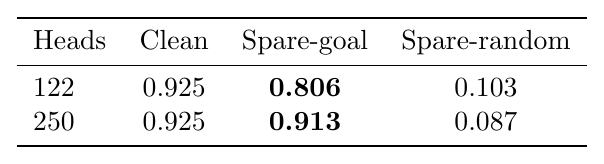

In [4]:
# ── Table: SUFFICIENCY — clean / spare-goal / spare-random (blind the rest) ──
SUF_LABEL={'baseline':'clean', 'ablated':'spare-goal', 'control':'spare-random'}
t=Table(title='Sufficiency — frontier implement-rate (n=253)')
t.add_column('budget')
for c in ['baseline','ablated','control']: t.add_column(SUF_LABEL[c], justify='right')
for b in BUDGETS:
    o=SUF[(b,'blind_span')]['overall']
    t.add_row(b, f"{o['baseline']:.3f}", f"[bold]{o['ablated']:.3f}[/bold]", f"[red]{o['control']:.3f}[/red]")
rich_print(t)

lines=[]
for b in BUDGETS:
    o=SUF[(b,'blind_span')]['overall']
    lines.append(f"{b.replace('goal','')} & {o['baseline']:.3f} & \\textbf{{{o['ablated']:.3f}}} & {o['control']:.3f} \\\\")
body='\n'.join(lines)
tex=('\\begin{tabular}{lccc}\n\\toprule\n'
     'Heads & Clean & Spare-goal & Spare-random \\\\\n\\midrule\n'
     + body + '\n\\bottomrule\n\\end{tabular}')
path=F.save_table(tex, GROUP, 'sufficiency'); print('wrote', path)
img=F.render_latex_table(tex)
img if img is not None else rich_print('[dim](latex preview unavailable)[/dim]')

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/ablation/necessity_sink.pdf


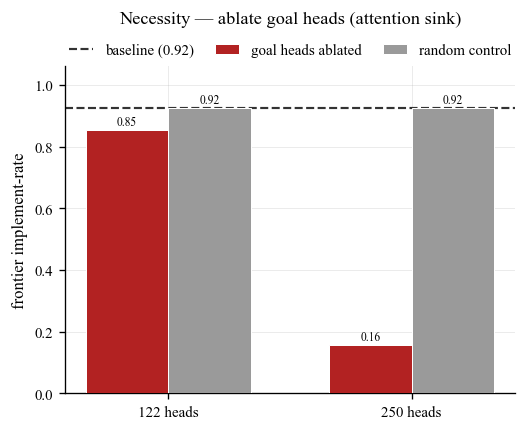

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/ablation/sufficiency_spare.pdf


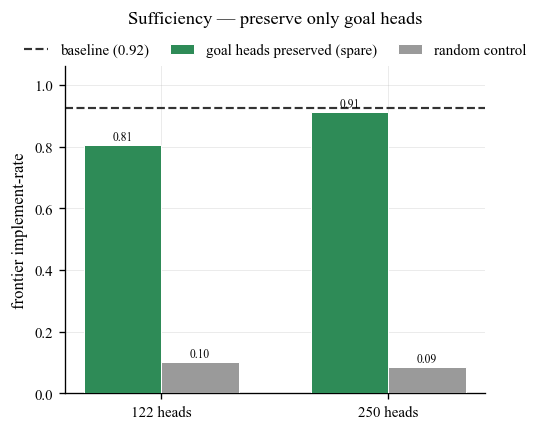

In [5]:
# ── Figures: necessity (sink only) + sufficiency, each across the 122/250 head sets ──
# firebrick = goal heads ABLATED (necessity); seagreen = goal heads PRESERVED/spare (sufficiency);
# gray = random control; baseline drawn as a horizontal dashed line.
FIRE='firebrick'; SEA='seagreen'; GRAY='#9a9a9a'
BUD=['goal122','goal250']; BLAB=['122 heads','250 heads']

def paired_fig(name, get_main, main_color, main_label, title):
    fig,ax=plt.subplots(figsize=(4.6,3.7)); x=np.arange(len(BUD)); w=0.34
    main=[get_main(b)['overall']['ablated'] for b in BUD]
    ctl =[get_main(b)['overall']['control'] for b in BUD]
    base=float(np.mean([get_main(b)['overall']['baseline'] for b in BUD]))
    ax.bar(x-w/2, main, w, color=main_color, edgecolor='white', linewidth=0.6, label=main_label, zorder=3)
    ax.bar(x+w/2, ctl,  w, color=GRAY,       edgecolor='white', linewidth=0.6, label='random control', zorder=3)
    ax.axhline(base, ls='--', lw=1.3, color='#333', zorder=2, label=f'baseline ({base:.2f})')
    for xi,(a,b) in enumerate(zip(main,ctl)):
        ax.text(xi-w/2,a+.015,f'{a:.2f}',ha='center',fontsize=7); ax.text(xi+w/2,b+.015,f'{b:.2f}',ha='center',fontsize=7)
    ax.set_xticks(x); ax.set_xticklabels(BLAB); ax.set_ylabel('frontier implement-rate'); ax.set_ylim(0,1.06)
    ax.set_title(title)
    F.legend_top(ax)
    fig.tight_layout(); print('saved',F.save_fig(fig,GROUP,name)); plt.show()

paired_fig('necessity_sink', lambda b: NEC[(b,'sink')], FIRE, 'goal heads ablated',
           'Necessity — ablate goal heads (attention sink)')
paired_fig('sufficiency_spare', lambda b: SUF[(b,'blind_span')], SEA, 'goal heads preserved (spare)',
           'Sufficiency — preserve only goal heads')